In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



In [ ]:
from google.colab import files

uploaded = files.upload()

Saving sample_data.csv to sample_data.csv


In [ ]:
df = pd.read_csv("sample_data.csv")

print("Dataset loaded successfully")

Dataset loaded successfully


In [ ]:
print("Number of rows and columns:")
print(df.shape)

Number of rows and columns:
(45832, 9)


In [ ]:
df.head()
print(df.columns)


Index(['Date', 'Time', 'Temperature Front', 'Humidity Front',
       'Temperature Middle', 'Humidity Middle', 'Temperature Back',
       'Humidity Back', 'Fan/Wet Wall State'],
      dtype='object')


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45832 entries, 0 to 45831
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Date                45832 non-null  object
 1   Time                45832 non-null  object
 2   Temperature Front   45832 non-null  int64 
 3   Humidity Front      45832 non-null  int64 
 4   Temperature Middle  45832 non-null  int64 
 5   Humidity Middle     45832 non-null  int64 
 6   Temperature Back    45832 non-null  int64 
 7   Humidity Back       45832 non-null  int64 
 8   Fan/Wet Wall State  45832 non-null  object
dtypes: int64(6), object(3)
memory usage: 3.1+ MB


In [ ]:
df.describe()

,Temperature Front,Humidity Front,Temperature Middle,Humidity Middle,Temperature Back,Humidity Back
count,45832.000000,45832.000000,45832.000000,45832.000000,45832.000000,45832.00000
mean,22.145815,75.746269,21.373036,72.038859,21.143677,78.80758
std,6.540386,27.335372,6.973167,23.860085,6.031879,22.78251
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,18.000000,52.000000,16.000000,51.000000,16.000000,58.00000
50%,21.000000,90.000000,20.000000,79.000000,20.000000,91.00000
75%,26.000000,98.000000,26.000000,94.000000,25.000000,99.00000
max,50.000000,100.000000,50.000000,100.000000,48.000000,100.00000


In [ ]:
print(df.isnull().sum())

Date                  0
Time                  0
Temperature Front     0
Humidity Front        0
Temperature Middle    0
Humidity Middle       0
Temperature Back      0
Humidity Back         0
Fan/Wet Wall State    0
dtype: int64


In [ ]:
sensor_columns = [
    "Temperature Front",
    "Humidity Front",
    "Temperature Middle",
    "Humidity Middle",
    "Temperature Back",
    "Humidity Back"
]

print((df[sensor_columns] == 0).sum())

Temperature Front      275
Humidity Front        1308
Temperature Middle     144
Humidity Middle        234
Temperature Back       172
Humidity Back          172
dtype: int64


In [ ]:
df_clean = df.copy()

In [ ]:
df_clean[sensor_columns] = df_clean[sensor_columns].replace(0, np.nan)

In [ ]:
df_clean[sensor_columns] = df_clean[sensor_columns].interpolate(
    method="linear",
    limit=2,
    limit_area="inside"
)

In [ ]:
print(df_clean[sensor_columns].isnull().sum())

Temperature Front     259
Humidity Front        717
Temperature Middle    133
Humidity Middle       143
Temperature Back      160
Humidity Back         160
dtype: int64


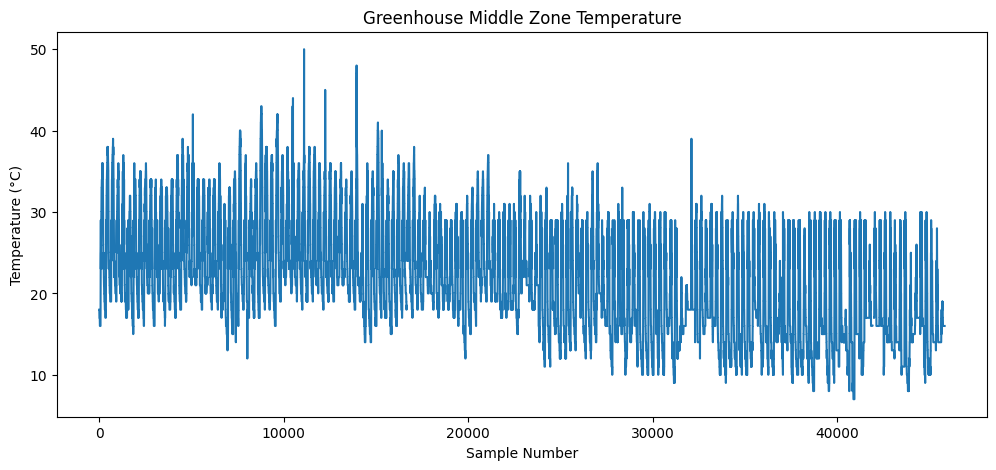

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(df_clean["Temperature Middle"])

plt.title("Greenhouse Middle Zone Temperature")
plt.xlabel("Sample Number")
plt.ylabel("Temperature (°C)")

plt.show()

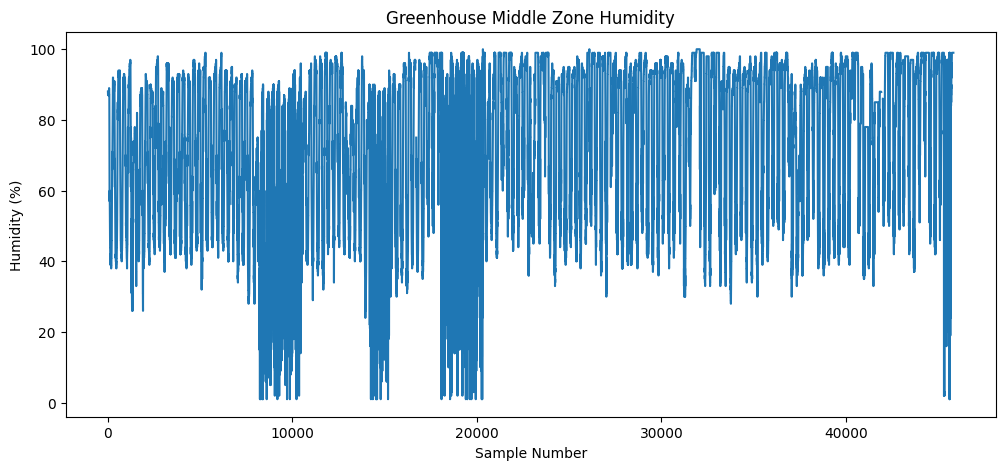

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(df_clean["Humidity Middle"])

plt.title("Greenhouse Middle Zone Humidity")
plt.xlabel("Sample Number")
plt.ylabel("Humidity (%)")

plt.show()

In [ ]:
print(df_clean["Fan/Wet Wall State"].value_counts())

Fan/Wet Wall State
F    32538
T    13294
Name: count, dtype: int64


In [ ]:
df_ml = df_clean.copy()

future_temperatures = pd.concat(
    [
        df_ml["Temperature Middle"].shift(-1),
        df_ml["Temperature Middle"].shift(-2),
        df_ml["Temperature Middle"].shift(-3)
    ],
    axis=1
)

df_ml["Overheating"] = (
    future_temperatures.gt(30).any(axis=1)
).astype(int)

In [ ]:
df_ml["Future_Temperature_Valid"] = (
    future_temperatures.notna().all(axis=1)
)

df_ml = df_ml[
    df_ml["Future_Temperature_Valid"]
].copy()

print(df_ml.shape)

(45692, 11)


In [ ]:
features = [
    "Temperature Front",
    "Humidity Front",
    "Temperature Middle",
    "Humidity Middle",
    "Temperature Back",
    "Humidity Back"
]

X = df_ml[features]

y = df_ml["Overheating"]

In [ ]:
n = len(df_ml)

train_end = int(n * 0.70)
validation_end = int(n * 0.85)

X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_val = X.iloc[train_end:validation_end]
y_val = y.iloc[train_end:validation_end]

X_test = X.iloc[validation_end:]
y_test = y.iloc[validation_end:]

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

Training records: 31984
Validation records: 6854
Testing records: 6854


In [ ]:
baseline_predictions = (
    X_test["Temperature Middle"] > 30
).astype(int)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Baseline Accuracy:",
      accuracy_score(y_test, baseline_predictions))

print("Baseline Precision:",
      precision_score(y_test, baseline_predictions,
                     zero_division=0))

print("Baseline Recall:",
      recall_score(y_test, baseline_predictions,
                  zero_division=0))

print("Baseline F1 Score:",
      f1_score(y_test, baseline_predictions,
               zero_division=0))

print("Baseline Confusion Matrix:")
print(confusion_matrix(y_test, baseline_predictions))

Baseline Accuracy: 1.0
Baseline Precision: 0.0
Baseline Recall: 0.0
Baseline F1 Score: 0.0
Baseline Confusion Matrix:
[[6854]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


In [ ]:
from sklearn.tree import DecisionTreeClassifier

In [ ]:
model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42,
    class_weight="balanced"
)

In [ ]:
model.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=5, random_state=42)

In [ ]:
validation_predictions = model.predict(X_val)

In [ ]:
print("Validation Accuracy:",
      accuracy_score(y_val, validation_predictions))

print("Validation Precision:",
      precision_score(y_val, validation_predictions,
                     zero_division=0))

print("Validation Recall:",
      recall_score(y_val, validation_predictions,
                  zero_division=0))

print("Validation F1 Score:",
      f1_score(y_val, validation_predictions,
               zero_division=0))

Validation Accuracy: 0.9817624744674642
Validation Precision: 0.42424242424242425
Validation Recall: 0.8842105263157894
Validation F1 Score: 0.5733788395904437


In [ ]:
test_predictions = model.predict(X_test)

In [ ]:
print("Test Accuracy:",
      accuracy_score(y_test, test_predictions))

print("Test Precision:",
      precision_score(y_test, test_predictions,
                     zero_division=0))

print("Test Recall:",
      recall_score(y_test, test_predictions,
                  zero_division=0))

print("Test F1 Score:",
      f1_score(y_test, test_predictions,
               zero_division=0))

print("Test Confusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

Test Accuracy: 0.9960606944849723
Test Precision: 0.0
Test Recall: 0.0
Test F1 Score: 0.0
Test Confusion Matrix:
[[6827   27]
 [   0    0]]


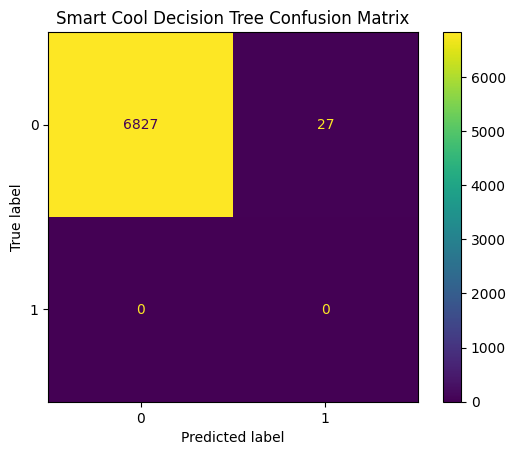

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions
)

plt.title("Smart Cool Decision Tree Confusion Matrix")
plt.show()

In [ ]:
import joblib

joblib.dump(model, "SmartCool_DecisionTree.pkl")

print("Model saved successfully")

Model saved successfully


In [ ]:
print("OVERHEATING DISTRIBUTION")

print("\nEntire dataset:")
print(y.value_counts())

print("\nTraining set:")
print(y_train.value_counts())

print("\nValidation set:")
print(y_val.value_counts())

print("\nTesting set:")
print(y_test.value_counts())

OVERHEATING DISTRIBUTION

Entire dataset:
Overheating
0    39887
1     5805
Name: count, dtype: int64

Training set:
Overheating
0    26274
1     5710
Name: count, dtype: int64

Validation set:
Overheating
0    6759
1      95
Name: count, dtype: int64

Testing set:
Overheating
0    6854
Name: count, dtype: int64


In [ ]:
# Divide the dataset into 10 chronological sections
target_values = y.reset_index(drop=True)

sections = np.array_split(target_values, 10)

for i, section in enumerate(sections):
    print(
        f"Section {i+1}: "
        f"Normal = {(section == 0).sum()}, "
        f"Overheating = {(section == 1).sum()}"
    )

Section 1: Normal = 3268, Overheating = 1302
Section 2: Normal = 3201, Overheating = 1369
Section 3: Normal = 3121, Overheating = 1448
Section 4: Normal = 3672, Overheating = 897
Section 5: Normal = 4141, Overheating = 428
Section 6: Normal = 4325, Overheating = 244
Section 7: Normal = 4547, Overheating = 22
Section 8: Normal = 4474, Overheating = 95
Section 9: Normal = 4569, Overheating = 0
Section 10: Normal = 4569, Overheating = 0


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:54: FutureWarning: 'Series.swapaxes' is deprecated and will be removed in a future version. Please use 'Series.transpose' instead.
  return bound(*args, **kwds)


In [ ]:
positive_positions = np.where(
    target_values.to_numpy() == 1
)[0]

print("First overheating position:", positive_positions.min())
print("Last overheating position:", positive_positions.max())

First overheating position: 119
Last overheating position: 36011


In [ ]:
sections = np.array_split(target_values, 10)

for i, section in enumerate(sections):
    print(
        f"Section {i+1}: "
        f"Normal = {(section == 0).sum()}, "
        f"Overheating = {(section == 1).sum()}, "
        f"Total = {len(section)}"
    )

Section 1: Normal = 3268, Overheating = 1302, Total = 4570
Section 2: Normal = 3201, Overheating = 1369, Total = 4570
Section 3: Normal = 3121, Overheating = 1448, Total = 4569
Section 4: Normal = 3672, Overheating = 897, Total = 4569
Section 5: Normal = 4141, Overheating = 428, Total = 4569
Section 6: Normal = 4325, Overheating = 244, Total = 4569
Section 7: Normal = 4547, Overheating = 22, Total = 4569
Section 8: Normal = 4474, Overheating = 95, Total = 4569
Section 9: Normal = 4569, Overheating = 0, Total = 4569
Section 10: Normal = 4569, Overheating = 0, Total = 4569


In [ ]:
# Reset the index to maintain chronological order
X = X.reset_index(drop=True)
y = y.reset_index(drop=True)

# Total number of records
n = len(X)

# Define chronological boundaries
train_end = int(n * 0.60)
validation_end = int(n * 0.70)
test_end = int(n * 0.80)

# Split the data
X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_val = X.iloc[train_end:validation_end]
y_val = y.iloc[train_end:validation_end]

X_test = X.iloc[validation_end:test_end]
y_test = y.iloc[validation_end:test_end]

# Display class distribution
print("Training distribution:")
print(y_train.value_counts())

print("\nValidation distribution:")
print(y_val.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training distribution:
Overheating
0    21727
1     5688
Name: count, dtype: int64

Validation distribution:
Overheating
0    4547
1      22
Name: count, dtype: int64

Testing distribution:
Overheating
0    4474
1      95
Name: count, dtype: int64


In [ ]:
# Reset the index to maintain chronological order
X = X.reset_index(drop=True)
y = y.reset_index(drop=True)

# Get the total number of records
n = len(X)

# Define the splitting points
train_end = int(n * 0.60)
validation_end = int(n * 0.70)
test_end = int(n * 0.80)

# Training data: first 60%
X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

# Validation data: next 10%
X_val = X.iloc[train_end:validation_end]
y_val = y.iloc[train_end:validation_end]

# Testing data: next 10%
X_test = X.iloc[validation_end:test_end]
y_test = y.iloc[validation_end:test_end]

# Display the class distribution
print("Training distribution:")
print(y_train.value_counts())

print("\nValidation distribution:")
print(y_val.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training distribution:
Overheating
0    21727
1     5688
Name: count, dtype: int64

Validation distribution:
Overheating
0    4547
1      22
Name: count, dtype: int64

Testing distribution:
Overheating
0    4474
1      95
Name: count, dtype: int64


In [ ]:
print("Missing values in training data:")
print(X_train.isnull().sum())

print("\nMissing values in validation data:")
print(X_val.isnull().sum())

print("\nMissing values in testing data:")
print(X_test.isnull().sum())

Missing values in training data:
Temperature Front     3
Humidity Front        3
Temperature Middle    1
Humidity Middle       6
Temperature Back      1
Humidity Back         1
dtype: int64

Missing values in validation data:
Temperature Front     88
Humidity Front        88
Temperature Middle     0
Humidity Middle        0
Temperature Back       0
Humidity Back          0
dtype: int64

Missing values in testing data:
Temperature Front     0
Humidity Front        0
Temperature Middle    0
Humidity Middle       0
Temperature Back      0
Humidity Back         0
dtype: int64


In [ ]:
# Fill missing sensor readings using the previous available reading
X_train = X_train.ffill()
X_val = X_val.ffill()
X_test = X_test.ffill()

# Check whether missing values remain
print("Training missing values:")
print(X_train.isnull().sum())

print("\nValidation missing values:")
print(X_val.isnull().sum())

print("\nTesting missing values:")
print(X_test.isnull().sum())

Training missing values:
Temperature Front     0
Humidity Front        0
Temperature Middle    0
Humidity Middle       0
Temperature Back      0
Humidity Back         0
dtype: int64

Validation missing values:
Temperature Front     0
Humidity Front        0
Temperature Middle    0
Humidity Middle       0
Temperature Back      0
Humidity Back         0
dtype: int64

Testing missing values:
Temperature Front     0
Humidity Front        0
Temperature Middle    0
Humidity Middle       0
Temperature Back      0
Humidity Back         0
dtype: int64


In [ ]:
# Create baseline predictions using the middle temperature

baseline_train = (X_train["Temperature Middle"] > 30).astype(int)

baseline_val = (X_val["Temperature Middle"] > 30).astype(int)

baseline_test = (X_test["Temperature Middle"] > 30).astype(int)

# Display the predictions
print("Baseline training predictions:")
print(baseline_train.value_counts())

print("\nBaseline validation predictions:")
print(baseline_val.value_counts())

print("\nBaseline testing predictions:")
print(baseline_test.value_counts())

Baseline training predictions:
Temperature Middle
0    22079
1     5336
Name: count, dtype: int64

Baseline validation predictions:
Temperature Middle
0    4553
1      16
Name: count, dtype: int64

Baseline testing predictions:
Temperature Middle
0    4497
1      72
Name: count, dtype: int64


In [ ]:
# Threshold-based baseline predictions

baseline_train = (X_train["Temperature Middle"] > 30).astype(int)
baseline_val = (X_val["Temperature Middle"] > 30).astype(int)
baseline_test = (X_test["Temperature Middle"] > 30).astype(int)

print("Baseline predictions created successfully.")

Baseline predictions created successfully.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("BASELINE MODEL RESULTS")

print("Accuracy:", accuracy_score(y_test, baseline_test))
print("Precision:", precision_score(y_test, baseline_test, zero_division=0))
print("Recall:", recall_score(y_test, baseline_test, zero_division=0))
print("F1 Score:", f1_score(y_test, baseline_test, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, baseline_test))

print("\nClassification Report:")
print(classification_report(y_test, baseline_test, zero_division=0))

BASELINE MODEL RESULTS
Accuracy: 0.9905887502735828
Precision: 0.8611111111111112
Recall: 0.6526315789473685
F1 Score: 0.7425149700598802

Confusion Matrix:
[[4464   10]
 [  33   62]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      4474
           1       0.86      0.65      0.74        95

    accuracy                           0.99      4569
   macro avg       0.93      0.83      0.87      4569
weighted avg       0.99      0.99      0.99      4569



In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42,
    class_weight="balanced"
)

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [ ]:
# Predictions on validation and testing data

y_val_pred = dt_model.predict(X_val)
y_test_pred = dt_model.predict(X_test)

print("Predictions completed!")

Predictions completed!


In [ ]:
print("DECISION TREE RESULTS")

print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_test_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_test_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, zero_division=0))

DECISION TREE RESULTS
Accuracy: 0.9765813088203108
Precision: 0.46629213483146065
Recall: 0.8736842105263158
F1 Score: 0.608058608058608

Confusion Matrix:
[[4379   95]
 [  12   83]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99      4474
           1       0.47      0.87      0.61        95

    accuracy                           0.98      4569
   macro avg       0.73      0.93      0.80      4569
weighted avg       0.99      0.98      0.98      4569



In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Baseline": [
        accuracy_score(y_test, baseline_test),
        precision_score(y_test, baseline_test, zero_division=0),
        recall_score(y_test, baseline_test, zero_division=0),
        f1_score(y_test, baseline_test, zero_division=0)
    ],
    "Decision Tree": [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred, zero_division=0),
        recall_score(y_test, y_test_pred, zero_division=0),
        f1_score(y_test, y_test_pred, zero_division=0)
    ]
})

print(results)

      Metric  Baseline  Decision Tree
0   Accuracy  0.990589       0.976581
1  Precision  0.861111       0.466292
2     Recall  0.652632       0.873684
3   F1 Score  0.742515       0.608059


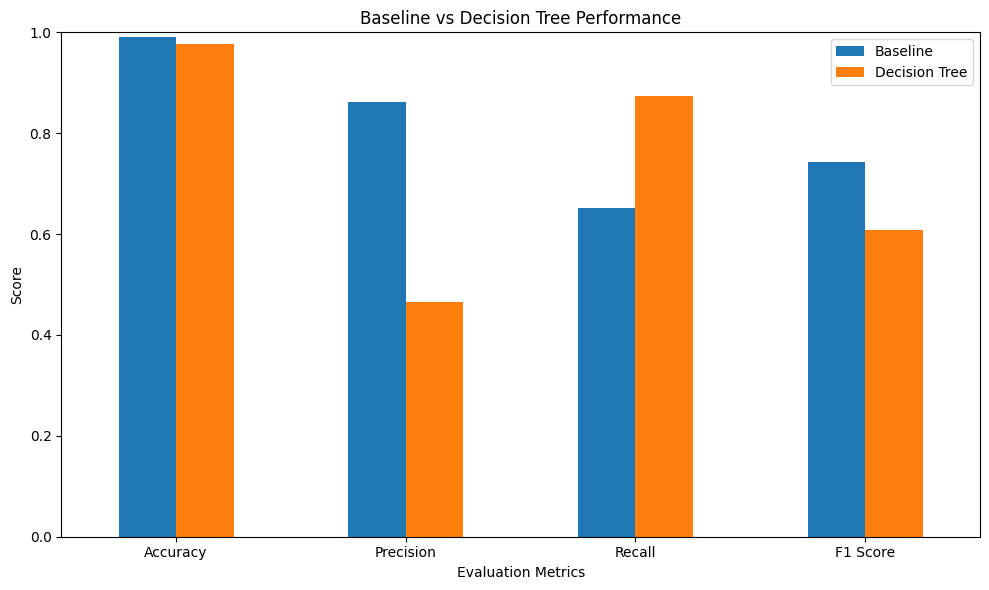

In [ ]:
import matplotlib.pyplot as plt

results_plot = results.set_index("Metric")

results_plot.plot(kind="bar", figsize=(10, 6))

plt.title("Baseline vs Decision Tree Performance")
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

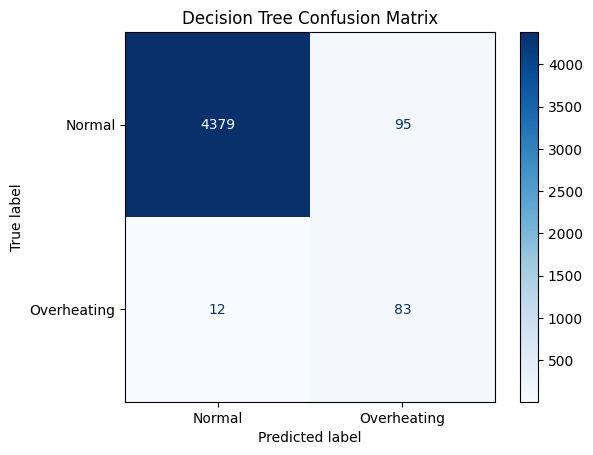

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["Normal", "Overheating"],
    cmap="Blues"
)

plt.title("Decision Tree Confusion Matrix")
plt.show()

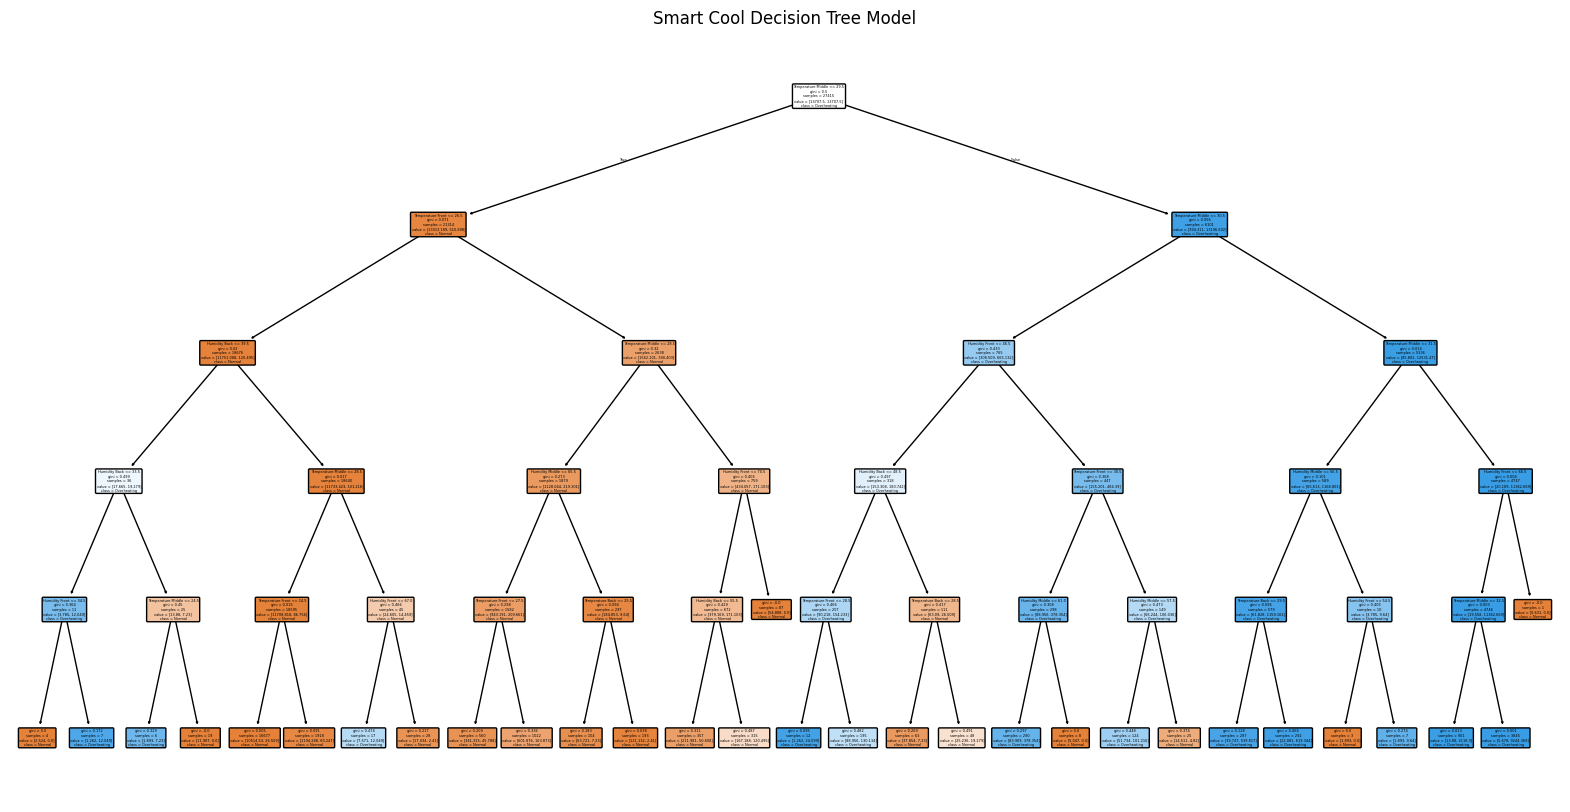